# TP1 — Construction d'un jeu de données PCG
**Objectif :** Explorer les datasets PhysioNet et Pascal, puis les fusionner en un seul dataset `ourdataset/train/{normal,abnormal}`

---
## 0. Imports & Configuration des chemins

In [7]:
import os
import shutil
import pandas as pd
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
from pathlib import Path
from collections import Counter

# Locate the project root from the notebook's current working directory.
PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "Data" / "dataset").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Could not find Data/dataset above {Path.cwd()}. "
        "Open/run this notebook from the CardioAgent-Ops project."
    )

DATASET_ROOT = PROJECT_ROOT / "Data" / "dataset"
PHYSIONET_ROOT = DATASET_ROOT / "physionet"
PASCAL_ROOT = DATASET_ROOT / "pascal"
OUTPUT_ROOT = PROJECT_ROOT / "ourdataset"

PHYSIONET_FOLDERS = ["training-a", "training-b", "training-c", "training-d", "training-e", "training-f"]
PASCAL_LABELS = {"normal": "normal", "murmur": "murmur", "extra": "extrastole"}
PASCAL_SETS = list(PASCAL_LABELS)

for required_path in (PHYSIONET_ROOT, PASCAL_ROOT):
    if not required_path.is_dir():
        raise FileNotFoundError(f"Required dataset folder not found: {required_path}")

print("Chemins détectés :")
print(f"  Projet    : {PROJECT_ROOT}")
print(f"  PhysioNet : {PHYSIONET_ROOT}")
print(f"  Pascal    : {PASCAL_ROOT}")
print(f"  Output    : {OUTPUT_ROOT}")

Chemins détectés :
  Projet    : c:\Users\azizb\Downloads\CardioAgent-Ops
  PhysioNet : c:\Users\azizb\Downloads\CardioAgent-Ops\Data\dataset\physionet
  Pascal    : c:\Users\azizb\Downloads\CardioAgent-Ops\Data\dataset\pascal
  Output    : c:\Users\azizb\Downloads\CardioAgent-Ops\ourdataset


---
## A. Exploration du dataset PhysioNet
### A1. Exploration du fichier CSV (labels)

In [8]:
# Chaque sous-dossier training-x contient un fichier REFERENCE.csv
# Format : filename, label  (-1 = Unknown, 1 = Normal, -1 = Abnormal)
# PhysioNet utilise : 1=Normal, -1=Abnormal

physio_dfs = []

for folder in PHYSIONET_FOLDERS:
    ref_path = os.path.join(PHYSIONET_ROOT, folder, "REFERENCE.csv")
    if os.path.exists(ref_path):
        df = pd.read_csv(ref_path, header=None, names=["filename", "label"])
        df["folder"] = folder
        df["label_str"] = df["label"].map({1: "normal", -1: "abnormal"})
        physio_dfs.append(df)
        print(f"[{folder}] — {len(df)} fichiers | Normal: {(df['label']==1).sum()} | Abnormal: {(df['label']==-1).sum()}")
    else:
        print(f"[{folder}] — REFERENCE.csv introuvable")

physio_df = pd.concat(physio_dfs, ignore_index=True)
print(f"\nTotal PhysioNet : {len(physio_df)} fichiers")
print(physio_df["label_str"].value_counts())

[training-a] — 409 fichiers | Normal: 292 | Abnormal: 117
[training-b] — 490 fichiers | Normal: 104 | Abnormal: 386
[training-c] — 31 fichiers | Normal: 24 | Abnormal: 7
[training-d] — 55 fichiers | Normal: 28 | Abnormal: 27
[training-e] — 2141 fichiers | Normal: 183 | Abnormal: 1958
[training-f] — 114 fichiers | Normal: 34 | Abnormal: 80

Total PhysioNet : 3240 fichiers
label_str
abnormal    2575
normal       665
Name: count, dtype: int64


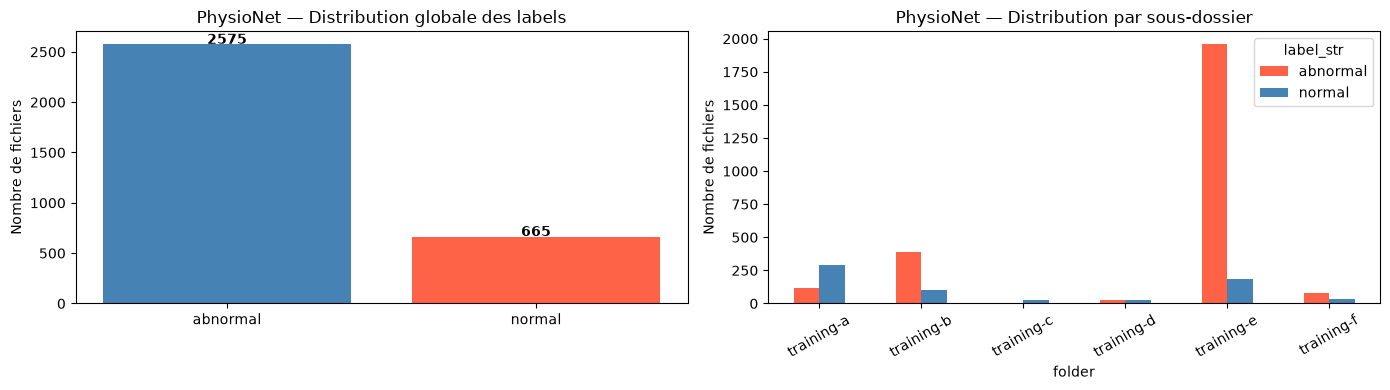

  filename  label      folder label_str
0    a0001      1  training-a    normal
1    a0002      1  training-a    normal
2    a0003      1  training-a    normal
3    a0004      1  training-a    normal
4    a0005      1  training-a    normal
5    a0006      1  training-a    normal
6    a0007     -1  training-a  abnormal
7    a0008      1  training-a    normal
8    a0009     -1  training-a  abnormal
9    a0010      1  training-a    normal


In [9]:
# Visualisation de la distribution des labels PhysioNet
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Distribution globale
counts = physio_df["label_str"].value_counts()
axes[0].bar(counts.index, counts.values, color=["steelblue", "tomato"])
axes[0].set_title("PhysioNet — Distribution globale des labels")
axes[0].set_ylabel("Nombre de fichiers")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 5, str(v), ha='center', fontweight='bold')

# Distribution par sous-dossier
folder_counts = physio_df.groupby(["folder", "label_str"]).size().unstack(fill_value=0)
folder_counts.plot(kind="bar", ax=axes[1], color=["tomato", "steelblue"])
axes[1].set_title("PhysioNet — Distribution par sous-dossier")
axes[1].set_ylabel("Nombre de fichiers")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()
print(physio_df.head(10))

### A2. Exploration des signaux WAV PhysioNet

In [10]:
# Fonction utilitaire : charger un wav PhysioNet
def get_physio_wav_path(row):
    return os.path.join(PHYSIONET_ROOT, row["folder"], row["filename"] + ".wav")

# Statistiques globales sur les durées et fréquences d'échantillonnage
durations = []
sample_rates = []

sample_rows = physio_df.groupby("label_str").apply(lambda x: x.sample(min(20, len(x)), random_state=42)).reset_index(drop=True)

for _, row in sample_rows.iterrows():
    wav_path = get_physio_wav_path(row)
    if os.path.exists(wav_path):
        y, sr = librosa.load(wav_path, sr=None)
        durations.append(len(y) / sr)
        sample_rates.append(sr)

print(f"Fréquences d'échantillonnage : {set(sample_rates)}")
print(f"Durée min : {min(durations):.2f}s | max : {max(durations):.2f}s | moyenne : {np.mean(durations):.2f}s")

Fréquences d'échantillonnage : {2000}
Durée min : 8.00s | max : 48.21s | moyenne : 23.73s


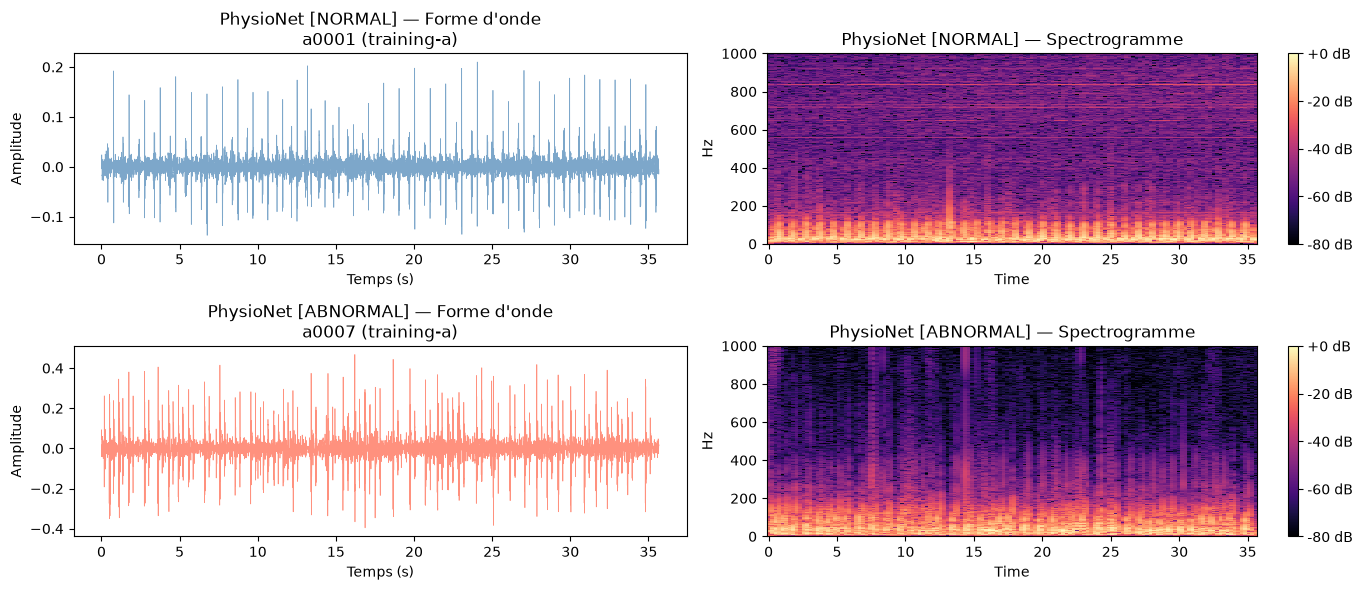

In [11]:
# Visualisation : 2 signaux (1 normal, 1 abnormal) depuis PhysioNet
fig, axes = plt.subplots(2, 2, figsize=(14, 6))

for idx, (label, color) in enumerate([("normal", "steelblue"), ("abnormal", "tomato")]):
    row = physio_df[physio_df["label_str"] == label].iloc[0]
    wav_path = get_physio_wav_path(row)
    
    if os.path.exists(wav_path):
        y, sr = librosa.load(wav_path, sr=None)
        t = np.linspace(0, len(y)/sr, len(y))
        
        # Forme d'onde
        axes[idx, 0].plot(t, y, color=color, alpha=0.7, linewidth=0.5)
        axes[idx, 0].set_title(f"PhysioNet [{label.upper()}] — Forme d'onde\n{row['filename']} ({row['folder']})")
        axes[idx, 0].set_xlabel("Temps (s)")
        axes[idx, 0].set_ylabel("Amplitude")
        
        # Spectrogramme
        D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
        img = librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz', ax=axes[idx, 1], cmap='magma')
        axes[idx, 1].set_title(f"PhysioNet [{label.upper()}] — Spectrogramme")
        fig.colorbar(img, ax=axes[idx, 1], format="%+2.0f dB")

plt.tight_layout()
plt.show()

In [12]:
# Écoute d'un signal normal PhysioNet
row_n = physio_df[physio_df["label_str"] == "normal"].iloc[0]
y_n, sr_n = librosa.load(get_physio_wav_path(row_n), sr=None)
print(f"Signal NORMAL : {row_n['filename']} | durée={len(y_n)/sr_n:.2f}s | sr={sr_n}Hz")
ipd.display(ipd.Audio(y_n, rate=sr_n))

# Écoute d'un signal abnormal PhysioNet
row_ab = physio_df[physio_df["label_str"] == "abnormal"].iloc[0]
y_ab, sr_ab = librosa.load(get_physio_wav_path(row_ab), sr=None)
print(f"Signal ABNORMAL : {row_ab['filename']} | durée={len(y_ab)/sr_ab:.2f}s | sr={sr_ab}Hz")
ipd.display(ipd.Audio(y_ab, rate=sr_ab))

Signal NORMAL : a0001 | durée=35.67s | sr=2000Hz


Signal ABNORMAL : a0007 | durée=35.67s | sr=2000Hz


---
## B. Exploration du dataset Pascal
### B1. Exploration des dossiers de classes Pascal

In [13]:
# Les WAV Pascal sont déjà rangés par classe dans normal/, murmur/ et extra/.
pascal_dfs = {}

for s in PASCAL_SETS:
    class_dir = PASCAL_ROOT / s
    if not class_dir.is_dir():
        raise FileNotFoundError(f"Pascal class folder not found: {class_dir}")

    wav_paths = sorted(class_dir.rglob("*.wav"))
    pascal_dfs[s] = pd.DataFrame({
        "filename": [path.relative_to(class_dir).as_posix() for path in wav_paths],
        "label": [PASCAL_LABELS[s]] * len(wav_paths),
    })
    print(f"\n[{s} / {PASCAL_LABELS[s]}] — {len(wav_paths)} fichiers WAV")
    print(pascal_dfs[s].head(5))


[normal / normal] — 351 fichiers WAV
                   filename   label
0   101_1305030823364_B.wav  normal
1   101_1305030823364_E.wav  normal
2   103_1305031931979_B.wav  normal
3  103_1305031931979_D1.wav  normal
4  103_1305031931979_D2.wav  normal

[murmur / murmur] — 129 fichiers WAV
                  filename   label
0  112_1306243000964_A.wav  murmur
1  112_1306243000964_B.wav  murmur
2  112_1306243000964_D.wav  murmur
3  116_1306258689913_A.wav  murmur
4  116_1306258689913_C.wav  murmur

[extra / extrastole] — 65 fichiers WAV
                   filename       label
0  127_1306764300147_C2.wav  extrastole
1   128_1306344005749_A.wav  extrastole
2   130_1306347376079_D.wav  extrastole
3  134_1306428161797_C1.wav  extrastole
4   138_1306762146980_B.wav  extrastole


In [14]:
# Identifier la colonne label dans Pascal (souvent 'label' ou dernière colonne)
def get_pascal_label_col(df):
    for col in ['label', 'Label', 'class', 'Class']:
        if col in df.columns:
            return col
    return df.columns[-1]  # fallback : dernière colonne

for s, df in pascal_dfs.items():
    lcol = get_pascal_label_col(df)
    print(f"[{s}] — colonne label détectée : '{lcol}'")
    print(df[lcol].value_counts())
    print()

[normal] — colonne label détectée : 'label'
label
normal    351
Name: count, dtype: int64

[murmur] — colonne label détectée : 'label'
label
murmur    129
Name: count, dtype: int64

[extra] — colonne label détectée : 'label'
label
extrastole    65
Name: count, dtype: int64



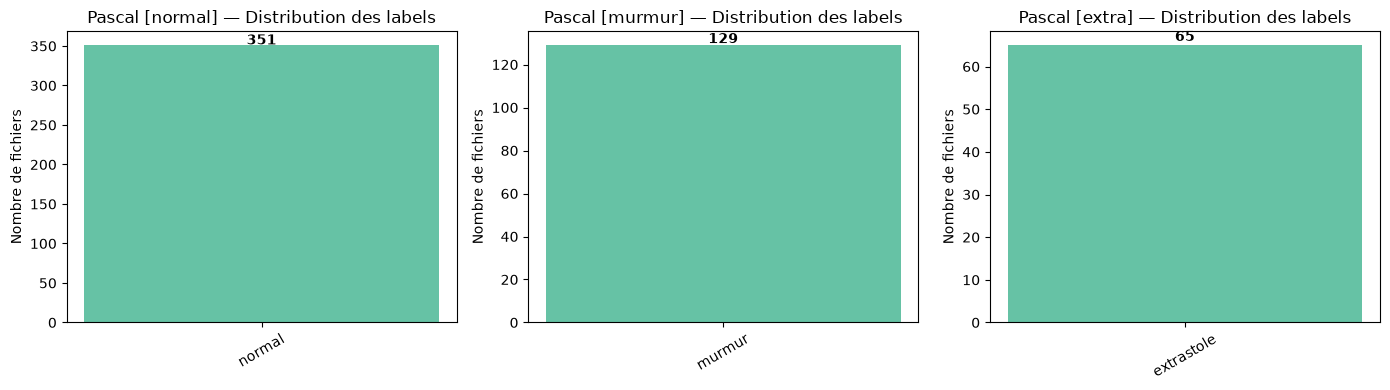

In [15]:
# Visualisation distribution Pascal
fig, axes = plt.subplots(1, len(pascal_dfs), figsize=(14, 4))
if len(pascal_dfs) == 1:
    axes = [axes]

for ax, (s, df) in zip(axes, pascal_dfs.items()):
    lcol = get_pascal_label_col(df)
    counts = df[lcol].value_counts()
    colors = plt.cm.Set2(np.linspace(0, 1, len(counts)))
    ax.bar(counts.index, counts.values, color=colors)
    ax.set_title(f"Pascal [{s}] — Distribution des labels")
    ax.set_ylabel("Nombre de fichiers")
    ax.tick_params(axis='x', rotation=30)
    for i, v in enumerate(counts.values):
        ax.text(i, v + 1, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### B2. Exploration des signaux WAV Pascal

In [16]:
# Résoudre un fichier WAV dans son dossier de classe Pascal
def get_pascal_wav_path(pascal_set, filename):
    # Le nom de fichier peut déjà avoir .wav ou non
    fname = filename if filename.endswith(".wav") else filename + ".wav"
    return os.path.join(PASCAL_ROOT, pascal_set, fname)

# Statistiques sur les WAVs Pascal
pascal_durations = []
pascal_srs = []

for s, df in pascal_dfs.items():
    lcol = get_pascal_label_col(df)
    fname_col = df.columns[0]  # première colonne = nom du fichier
    sample = df.sample(min(15, len(df)), random_state=42)
    for _, row in sample.iterrows():
        wav_path = get_pascal_wav_path(s, str(row[fname_col]))
        if os.path.exists(wav_path):
            y, sr = librosa.load(wav_path, sr=None)
            pascal_durations.append(len(y)/sr)
            pascal_srs.append(sr)

if pascal_durations:
    print(f"Pascal — Fréquences d'échantillonnage : {set(pascal_srs)}")
    print(f"Durée min : {min(pascal_durations):.2f}s | max : {max(pascal_durations):.2f}s | moyenne : {np.mean(pascal_durations):.2f}s")
else:
    print("Aucun fichier WAV trouvé — vérifiez les chemins")

Pascal — Fréquences d'échantillonnage : {4000, 44100}
Durée min : 1.38s | max : 27.87s | moyenne : 7.82s


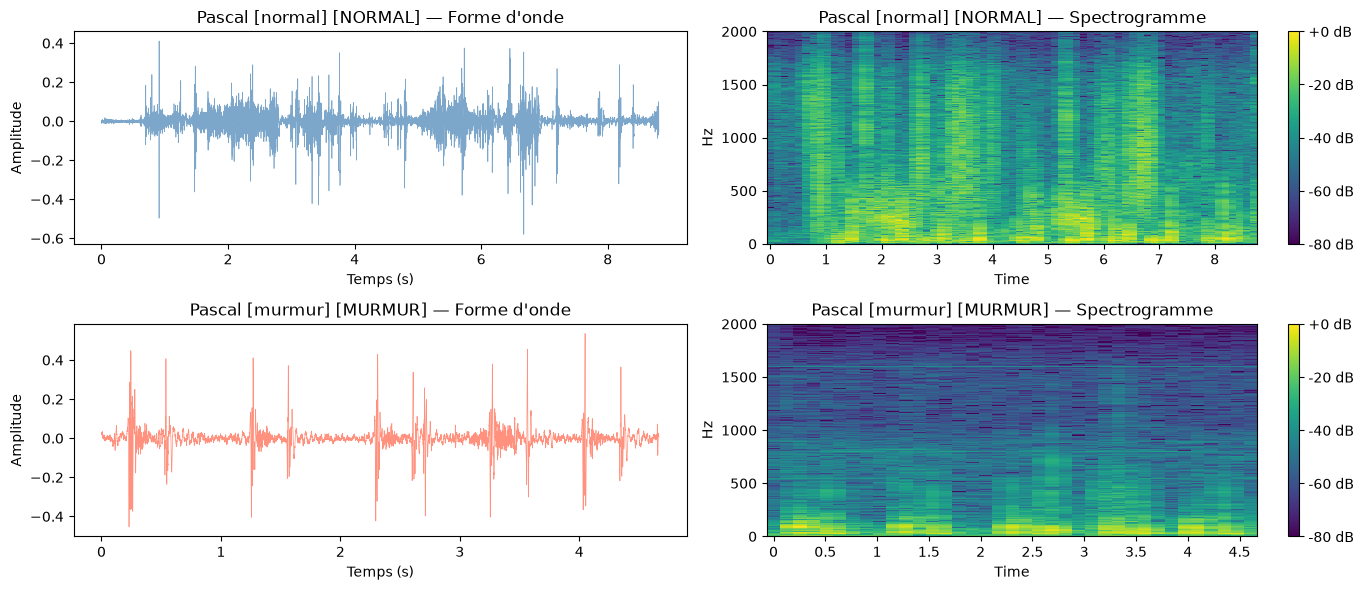

In [17]:
# Visualisation de signaux Pascal
pascal_labels_to_show = ["normal", "murmur"]

fig, axes = plt.subplots(len(pascal_labels_to_show), 2, figsize=(14, 6))
colors = {"normal": "steelblue", "murmur": "tomato", "extrastole": "orange", "artifact": "gray"}

found_any = False
for idx, target_label in enumerate(pascal_labels_to_show):
    for s, df in pascal_dfs.items():
        lcol = get_pascal_label_col(df)
        fname_col = df.columns[0]
        subset = df[df[lcol].str.lower().str.contains(target_label, na=False)]
        if len(subset) == 0:
            continue
        row = subset.iloc[0]
        wav_path = get_pascal_wav_path(s, str(row[fname_col]))
        if os.path.exists(wav_path):
            y, sr = librosa.load(wav_path, sr=None)
            t = np.linspace(0, len(y)/sr, len(y))
            c = colors.get(target_label, "purple")
            
            axes[idx, 0].plot(t, y, color=c, alpha=0.7, linewidth=0.5)
            axes[idx, 0].set_title(f"Pascal [{s}] [{target_label.upper()}] — Forme d'onde")
            axes[idx, 0].set_xlabel("Temps (s)")
            axes[idx, 0].set_ylabel("Amplitude")
            
            D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
            img = librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz', ax=axes[idx, 1], cmap='viridis')
            axes[idx, 1].set_title(f"Pascal [{s}] [{target_label.upper()}] — Spectrogramme")
            fig.colorbar(img, ax=axes[idx, 1], format="%+2.0f dB")
            found_any = True
            break

if found_any:
    plt.tight_layout()
    plt.show()
else:
    print("Aucun fichier WAV trouvé pour les labels sélectionnés.")

---
## C. Fusion des datasets — Construction de `ourdataset/train/`

**Règle de fusion :**
- **normal** → `ourdataset/train/normal/`  
- **murmur** + **extrastole** → `ourdataset/train/abnormal/`
- Les labels **artifact** et **unlabelled** de Pascal sont exclus

In [18]:
# Créer la structure de dossiers ourdataset
normal_dir   = os.path.join(OUTPUT_ROOT, "train", "normal")
abnormal_dir = os.path.join(OUTPUT_ROOT, "train", "abnormal")

os.makedirs(normal_dir,   exist_ok=True)
os.makedirs(abnormal_dir, exist_ok=True)

print("Structure créée :")
print(f"  {normal_dir}")
print(f"  {abnormal_dir}")

Structure créée :
  c:\Users\azizb\Downloads\CardioAgent-Ops\ourdataset\train\normal
  c:\Users\azizb\Downloads\CardioAgent-Ops\ourdataset\train\abnormal


In [19]:
# ── Copie des fichiers PhysioNet ──
physio_copied = {"normal": 0, "abnormal": 0, "skipped": 0}

for _, row in physio_df.iterrows():
    src = get_physio_wav_path(row)
    if not os.path.exists(src):
        physio_copied["skipped"] += 1
        continue
    
    dest_folder = normal_dir if row["label"] == 1 else abnormal_dir
    # Préfixe "physio_" pour éviter les collisions de noms
    dest_name = f"physio_{row['folder']}_{row['filename']}.wav"
    dest = os.path.join(dest_folder, dest_name)
    
    if not os.path.exists(dest):  # ne pas recopier si déjà présent
        shutil.copy2(src, dest)
    
    key = "normal" if row["label"] == 1 else "abnormal"
    physio_copied[key] += 1

print("PhysioNet copié :")
print(f"  Normal   : {physio_copied['normal']}")
print(f"  Abnormal : {physio_copied['abnormal']}")
print(f"  Ignorés  : {physio_copied['skipped']}")

PhysioNet copié :
  Normal   : 665
  Abnormal : 2575
  Ignorés  : 0


In [20]:
# ── Copie des fichiers Pascal ──
# Mapping : normal→normal | murmur/extrastole→abnormal | artifact/unlabelled→ignoré
PASCAL_LABEL_MAP = {
    "normal":     "normal",
    "murmur":     "abnormal",
    "extrastole": "abnormal",
    "artifact":   None,       # exclu
    "unlabelled": None,       # exclu
    "unknown":    None,       # exclu
}

pascal_copied = {"normal": 0, "abnormal": 0, "skipped": 0, "excluded": 0}

for s, df in pascal_dfs.items():
    lcol = get_pascal_label_col(df)
    fname_col = df.columns[0]
    
    for _, row in df.iterrows():
        raw_label = str(row[lcol]).strip().lower()
        mapped = PASCAL_LABEL_MAP.get(raw_label)
        
        if mapped is None:
            pascal_copied["excluded"] += 1
            continue
        
        src = get_pascal_wav_path(s, str(row[fname_col]))
        if not os.path.exists(src):
            pascal_copied["skipped"] += 1
            continue
        
        dest_folder = normal_dir if mapped == "normal" else abnormal_dir
        dest_name = f"pascal_{s}_{os.path.basename(src)}"
        dest = os.path.join(dest_folder, dest_name)
        
        if not os.path.exists(dest):
            shutil.copy2(src, dest)
        
        pascal_copied[mapped] += 1

print("Pascal copié :")
print(f"  Normal   : {pascal_copied['normal']}")
print(f"  Abnormal : {pascal_copied['abnormal']}")
print(f"  Ignorés  : {pascal_copied['skipped']}")
print(f"  Exclus   : {pascal_copied['excluded']} (artifact/unlabelled)")

Pascal copié :
  Normal   : 351
  Abnormal : 194
  Ignorés  : 0
  Exclus   : 0 (artifact/unlabelled)


══════════════════════════════════════
   STRUCTURE FINALE DE OURDATASET
══════════════════════════════════════
ourdataset/
└── train/
    ├── normal/    →  1016 fichiers WAV
    └── abnormal/  →  2769 fichiers WAV
                     ─────────────────
    TOTAL          →  3785 fichiers WAV


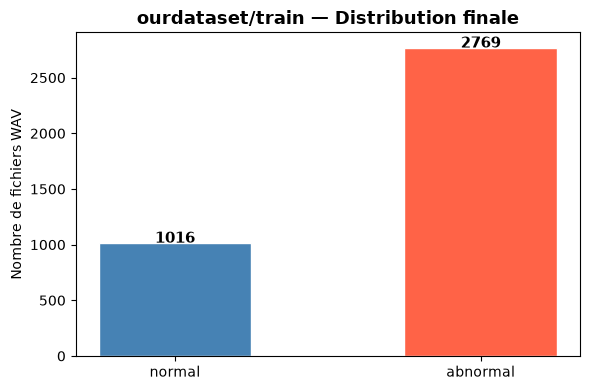

In [21]:
# ── Résumé final de ourdataset ──
n_normal   = len(os.listdir(normal_dir))
n_abnormal = len(os.listdir(abnormal_dir))
total      = n_normal + n_abnormal

print("══════════════════════════════════════")
print("   STRUCTURE FINALE DE OURDATASET")
print("══════════════════════════════════════")
print(f"ourdataset/")
print(f"└── train/")
print(f"    ├── normal/    → {n_normal:>5} fichiers WAV")
print(f"    └── abnormal/  → {n_abnormal:>5} fichiers WAV")
print(f"                     ─────────────────")
print(f"    TOTAL          → {total:>5} fichiers WAV")

# Visualisation finale
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["normal", "abnormal"], [n_normal, n_abnormal],
              color=["steelblue", "tomato"], edgecolor="white", width=0.5)
ax.set_title("ourdataset/train — Distribution finale", fontsize=13, fontweight='bold')
ax.set_ylabel("Nombre de fichiers WAV")
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            str(int(bar.get_height())), ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

In [22]:
# Vérification : lister les 5 premiers fichiers de chaque classe
print("Exemples — normal :")
for f in sorted(os.listdir(normal_dir))[:5]:
    print(f"  {f}")

print("\nExemples — abnormal :")
for f in sorted(os.listdir(abnormal_dir))[:5]:
    print(f"  {f}")

Exemples — normal :
  pascal_normal_101_1305030823364_B.wav
  pascal_normal_101_1305030823364_E.wav
  pascal_normal_103_1305031931979_B.wav
  pascal_normal_103_1305031931979_D1.wav
  pascal_normal_103_1305031931979_D2.wav

Exemples — abnormal :
  pascal_extra_127_1306764300147_C2.wav
  pascal_extra_128_1306344005749_A.wav
  pascal_extra_130_1306347376079_D.wav
  pascal_extra_134_1306428161797_C1.wav
  pascal_extra_138_1306762146980_B.wav
